# Simple Time series Analysis on my portfolio
This is a basic time series EDA and basic portfolio analysis for my first portfolio (currently losing money xd)

# 1. Libs and config

In [36]:
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from reporting import perfomance_metrics
from utils import daily_index

from matplotlib.ticker import PercentFormatter, StrMethodFormatter

# 2. Data

In [2]:
# historical transacons
transactions = pd.DataFrame(
    [
        ("2026-09-08", None, "deposit", 1067.00),
        ("2026-09-09", "VT", "buy", -500.47),
        ("2026-09-10", "NVDA", "buy", -53.50),
        ("2026-09-10", "GOOGL", "buy", -53.50),
        ("2026-09-10", "AMZN", "buy", -80.15),
        ("2026-09-10", "XLV", "buy", -133.50),
        ("2026-09-10", "FIDU", "buy", -133.50),
        ("2026-09-10", "VT", "buy", -32.23),
        ("2026-09-10", "TSM", "buy", -80.15),
        ("2026-09-23", "VT", "dividend", 0.95),
        ("2026-09-23", "FIDU", "dividend", 0.21),
        ("2026-09-24", "XLV", "dividend", 0.36),
        ("2026-10-09", "TSM", "dividend", 0.16),
    ],
    columns=["date", "ticker", "type", "amount"],
)

transactions["date"] = pd.to_datetime(transactions["date"])

transactions

,date,ticker,type,amount
0,2026-09-08,NaN,deposit,1067.00
1,2026-09-09,VT,buy,-500.47
2,2026-09-10,NVDA,buy,-53.50
3,2026-09-10,GOOGL,buy,-53.50
4,2026-09-10,AMZN,buy,-80.15
5,2026-09-10,XLV,buy,-133.50
6,2026-09-10,FIDU,buy,-133.50
7,2026-09-10,VT,buy,-32.23
8,2026-09-10,TSM,buy,-80.15
9,2026-09-23,VT,dividend,0.95


In [3]:
# current holding

holdings = pd.DataFrame(
    [
        ("VT", 3.32195, 492.57, -39.87, -0.0748),
        ("XLV", 0.80476, 148.01, 14.67, 0.1100),
        ("FIDU", 1.46780, 126.68, -6.66, -0.0499),
        ("AMZN", 0.31714, 78.25, -1.74, -0.0218),
        ("TSM", 0.18514, 64.31, -15.68, -0.1960),
        ("GOOGL", 0.16142, 44.38, -8.96, -0.1680),
        ("NVDA", 0.24438, 36.96, -16.38, -0.3071),
    ],
    columns=["ticker", "quantity", "market_value", "reported_pnl", "reported_return"],
)

holdings["current_price"] = holdings["market_value"] / holdings["quantity"]

holdings

,ticker,quantity,market_value,reported_pnl,reported_return,current_price
0,VT,3.32195,492.57,-39.87,-0.0748,148.277367
1,XLV,0.80476,148.01,14.67,0.1100,183.918187
2,FIDU,1.46780,126.68,-6.66,-0.0499,86.306036
3,AMZN,0.31714,78.25,-1.74,-0.0218,246.736457
4,TSM,0.18514,64.31,-15.68,-0.1960,347.358756
5,GOOGL,0.16142,44.38,-8.96,-0.1680,274.934952
6,NVDA,0.24438,36.96,-16.38,-0.3071,151.239872


In [4]:
# Downloading historical data
tickers = holdings["ticker"].unique()

data = {}

for ticker in tickers:
    asset = yf.Ticker(ticker)

    asset_history = asset.history(
        period="10y",
        interval="1d",
        auto_adjust=False,
    )

    data[ticker] = asset_history

# S&P data
sp = yf.Ticker("SPY")
sp_history = sp.history(period="10y", interval="1d", auto_adjust=False)

# FRED data for risk free rate proxy (daily)

series = "DGS3MO"
url = "https://fred.stlouisfed.org/graph/" f"fredgraph.csv?id={series}"
rf = pd.read_csv(url, index_col=0, parse_dates=True)
display(rf.tail())

,DGS3MO
observation_date,
2026-11-19,4.34
2026-11-20,4.32
2026-11-23,4.37
2026-11-24,4.36
2026-11-25,4.34


In [6]:
prices = pd.DataFrame({ticker: data[ticker]["Adj Close"] for ticker in tickers})

benchmark = pd.DataFrame(
    {"VT": data["VT"]["Adj Close"], "SPY": sp_history["Adj Close"]}
)
display(prices.head())
display(benchmark.head())

,VT,XLV,FIDU,AMZN,TSM,GOOGL,NVDA
Date,,,,,,,
2016-11-28 00:00:00-05:00,48.980709,58.333820,27.824657,38.338501,23.517254,38.919155,2.312243
2016-11-29 00:00:00-05:00,49.078114,58.714481,27.807390,38.125999,23.430037,39.099941,2.291113
2016-11-30 00:00:00-05:00,49.005051,58.156174,27.885071,37.528500,23.541044,38.428326,2.265314
2016-12-01 00:00:00-05:00,48.785839,57.733234,28.040415,37.182499,22.637144,37.856270,2.153278
2016-12-02 00:00:00-05:00,48.891392,57.868565,27.988634,37.016998,22.882942,37.862709,2.173179


,VT,SPY
Date,,
2016-11-28 00:00:00-05:00,48.980709,188.288879
2016-11-29 00:00:00-05:00,49.078114,188.656143
2016-11-30 00:00:00-05:00,49.005051,188.203522
2016-12-01 00:00:00-05:00,48.785839,187.511734
2016-12-02 00:00:00-05:00,48.891392,187.605667


In [7]:
# checking some general stats

display(prices.isna().sum())
display(benchmark.isna().sum())

print(f"Min date: {prices.index.min():%Y-%m-%d}")
print(f"Max date: {prices.index.max():%Y-%m-%d}")

VT       0
XLV      0
FIDU     0
AMZN     0
TSM      0
GOOGL    0
NVDA     0
dtype: int64

VT     0
SPY    0
dtype: int64

Min date: 2016-11-28
Max date: 2026-11-27


In [8]:
sp_history

,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Capital Gains
Date,,,,,,,,,
2016-11-28 00:00:00-05:00,221.160004,221.479996,220.360001,220.479996,188.288879,76572500,0.0,0.0,0.0
2016-11-29 00:00:00-05:00,220.520004,221.440002,220.169998,220.910004,188.656143,69886700,0.0,0.0,0.0
2016-11-30 00:00:00-05:00,221.630005,221.820007,220.309998,220.380005,188.203522,113291800,0.0,0.0,0.0
2016-12-01 00:00:00-05:00,220.729996,220.729996,219.149994,219.570007,187.511734,79040500,0.0,0.0,0.0
2016-12-02 00:00:00-05:00,219.669998,220.250000,219.259995,219.679993,187.605667,74840300,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
2026-11-20 00:00:00-05:00,713.559998,718.289978,686.750000,689.809998,689.809998,151413300,0.0,0.0,0.0
2026-11-23 00:00:00-05:00,724.330017,727.979980,713.530029,722.289978,722.289978,88283800,0.0,0.0,0.0
2026-11-24 00:00:00-05:00,715.150024,720.929993,712.140015,718.780029,718.780029,64343200,0.0,0.0,0.0


In [9]:
holdings

,ticker,quantity,market_value,reported_pnl,reported_return,current_price
0,VT,3.32195,492.57,-39.87,-0.0748,148.277367
1,XLV,0.80476,148.01,14.67,0.1100,183.918187
2,FIDU,1.46780,126.68,-6.66,-0.0499,86.306036
3,AMZN,0.31714,78.25,-1.74,-0.0218,246.736457
4,TSM,0.18514,64.31,-15.68,-0.1960,347.358756
5,GOOGL,0.16142,44.38,-8.96,-0.1680,274.934952
6,NVDA,0.24438,36.96,-16.38,-0.3071,151.239872


In [10]:
close_prices = pd.DataFrame({ticker: data[ticker]["Close"] for ticker in tickers})

portfolio_prices = close_prices.loc["2026-09-10":]

quantities = holdings.set_index("ticker")["quantity"]
print(quantities)
display(portfolio_prices.head())

ticker
VT       3.32195
XLV      0.80476
FIDU     1.46780
AMZN     0.31714
TSM      0.18514
GOOGL    0.16142
NVDA     0.24438
Name: quantity, dtype: float64


,VT,XLV,FIDU,AMZN,TSM,GOOGL,NVDA
Date,,,,,,,
2026-09-10 00:00:00-04:00,158.529999,165.660004,90.540001,251.889999,428.029999,332.600006,218.360001
2026-09-11 00:00:00-04:00,159.940002,165.360001,91.580002,256.779999,433.239990,338.500000,218.289993
2026-09-14 00:00:00-04:00,158.729996,167.750000,90.230003,253.539993,418.010010,349.390015,210.960007
2026-09-15 00:00:00-04:00,158.029999,167.660004,89.580002,248.419998,413.750000,344.980011,212.169998
2026-09-16 00:00:00-04:00,157.410004,167.770004,89.559998,245.960007,417.720001,342.869995,213.899994


# 3. Questions

## 3.1. How has my portfolio evolved since inception? 

In [11]:
market_value = portfolio_prices * quantities
market_value["total"] = market_value.sum(axis=1)

market_value.tail()

,VT,XLV,FIDU,AMZN,TSM,GOOGL,NVDA,total
Date,,,,,,,,
2026-11-20 00:00:00-05:00,471.982662,142.635667,121.372386,78.276497,59.005968,42.823113,30.677021,946.773314
2026-11-23 00:00:00-05:00,492.346232,144.390038,126.289513,80.994384,67.316905,45.536583,40.334920,997.208575
2026-11-24 00:00:00-05:00,490.186934,148.655268,125.306090,80.011248,64.650890,45.044249,37.971766,991.826445
2026-11-25 00:00:00-05:00,490.120481,147.818311,126.685814,77.518528,63.380827,44.083803,36.485935,986.093699
2026-11-27 00:00:00-05:00,498.890427,148.236790,128.887514,80.591615,65.417367,44.384042,36.776748,1003.184502


In [ ]:
TRADING_DAYS = 252
# Aggregate dividends by payment date
dividends = transactions.query("type == 'dividend'").groupby("date")["amount"].sum()

if market_value.index.tz is not None:
    dividends.index = dividends.index.tz_localize(market_value.index.tz)

# consturc cumulative dividend cash
cumulative_dividends = (
    dividends.reindex(market_value.index.union(dividends.index), fill_value=0)
    .sort_index()
    .cumsum()
    .reindex(market_value.index)
)

# Reconstruct total portfolio wealth
portfolio_wealth = market_value["total"] + cumulative_dividends
portfolio_returns = portfolio_wealth.pct_change().dropna()
portfolio_wealth.tail()

portfolio_returns.index = (
    pd.to_datetime(portfolio_returns.index).tz_localize(None).normalize()
)

rf["daily_rf"] = (1 + rf["DGS3MO"] / 100) ** (1 / TRADING_DAYS) - 1

# Align risk-free rates with portfolio valuation dates
rf_aligned = (
    rf["daily_rf"]
    .sort_index()
    .dropna()
    .reindex(portfolio_wealth.index.tz_localize(None).normalize(), method="ffill")
    .shift(1)
)

# Construct excess return series
excess_return = (portfolio_returns - rf_aligned).dropna()

excess_return_mean = excess_return.mean()
excess_return_std = excess_return.std()

Date
2026-11-20 00:00:00-05:00     948.453314
2026-11-23 00:00:00-05:00     998.888575
2026-11-24 00:00:00-05:00     993.506445
2026-11-25 00:00:00-05:00     987.773699
2026-11-27 00:00:00-05:00    1004.864502
dtype: float64

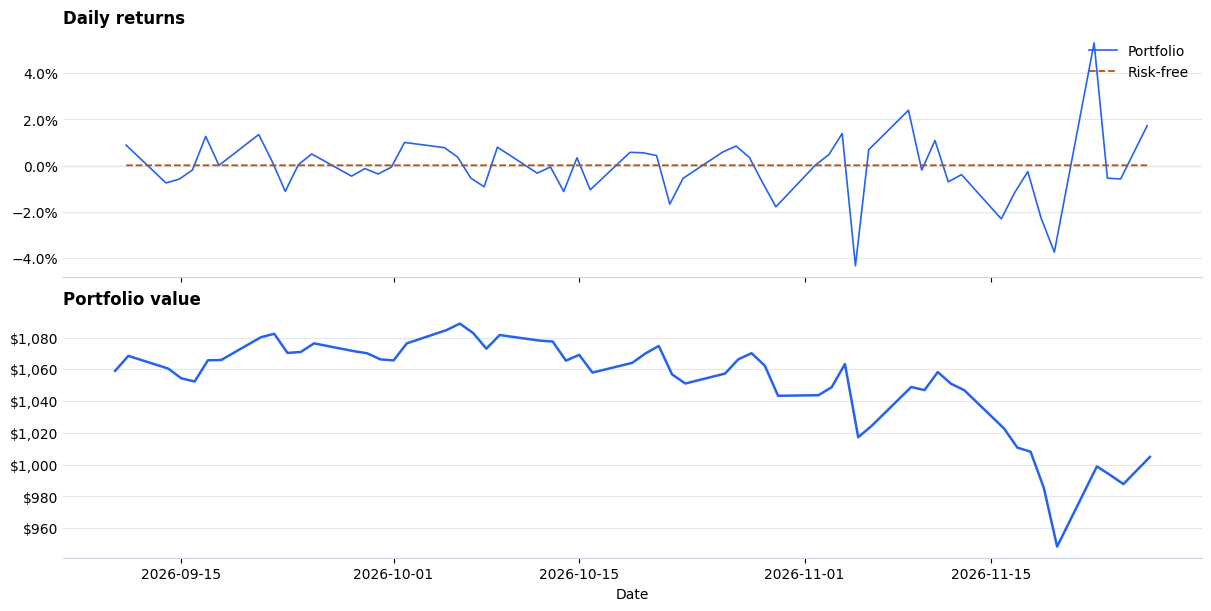

In [33]:
fig, (ax_returns, ax_wealth) = plt.subplots(
    2, 1, figsize=(12, 6), sharex=True, layout="constrained"
)

ax_returns.plot(portfolio_returns, color="#2563EB", lw=1.2, label="Portfolio")
ax_returns.plot(rf_aligned, color="#B45309", lw=1.3, ls="--", label="Risk-free")
ax_returns.axhline(0, color="#94A3B8", lw=0.8, zorder=0)
ax_returns.set_title("Daily returns", loc="left", fontweight="bold")
ax_returns.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax_returns.legend(frameon=False, loc="upper right")

ax_wealth.plot(portfolio_wealth, color="#2563EB", lw=1.8)
ax_wealth.set_title("Portfolio value", loc="left", fontweight="bold")
ax_wealth.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax_wealth.set_xlabel("Date")

for ax in (ax_returns, ax_wealth):
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E2E8F0", linewidth=0.8)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#CBD5E1")
    ax.tick_params(axis="y", length=0)

plt.show()

In [14]:
portfolio_metrics = perfomance_metrics(
    portfolio_wealth,
    portfolio_returns,
    rf_aligned,
    periods_per_year=252,
    target_return=0,
)

metrics_by_investment = {"Hapi portfolio": portfolio_metrics}
metrics_df = pd.DataFrame(metrics_by_investment)

display(metrics_df)

,Hapi portfolio
Initial_value,1059.020866
Final_value,1004.864502
Holding_period_return,-0.051138
Arimetic_mean,-0.000856
Geometric_mean,-0.000954
Annualized_aritmetic_mean,-0.194014
Daily_volatiliy,0.014163
Annualized_volatility,0.224825
Worst_period_return,-0.043314
Max_drawdown,-0.128869


## 3.2. How has my portfolio performed relative to the market?

In [53]:
portfolio_wealth = daily_index(portfolio_wealth)
benchmark_prices = daily_index(benchmark).reindex(portfolio_wealth.index)

benchmark_wealth = portfolio_wealth.iloc[0] * (
    benchmark_prices / benchmark_prices.iloc[0]
)

benchmark_returns = benchmark_prices.pct_change().dropna()
rf_aligned = rf_aligned.dropna()

for ticker in benchmark_prices.columns:
    prices = benchmark_prices[ticker]
    wealth = portfolio_wealth.iloc[0] * (prices / prices.iloc[0])
    returns = prices.pct_change(fill_method=None).dropna()

    metrics_df[ticker] = pd.Series(
        perfomance_metrics(
            wealth,
            returns,
            rf_aligned.reindex(returns.index),
            periods_per_year=252,
            target_return=0,
        )
    )

display(metrics_df)

,Hapi portfolio,VT,SPY
Initial_value,1059.020866,1059.020866,1059.020866
Final_value,1004.864502,1005.818112,1020.309819
Holding_period_return,-0.051138,-0.050238,-0.036554
Arimetic_mean,-0.000856,-0.000855,-0.000591
Geometric_mean,-0.000954,-0.000937,-0.000677
Annualized_aritmetic_mean,-0.194014,-0.193948,-0.138365
Daily_volatiliy,0.014163,0.012878,0.013228
Annualized_volatility,0.224825,0.204432,0.209983
Worst_period_return,-0.043314,-0.040745,-0.044092
Max_drawdown,-0.128869,-0.118829,-0.114595


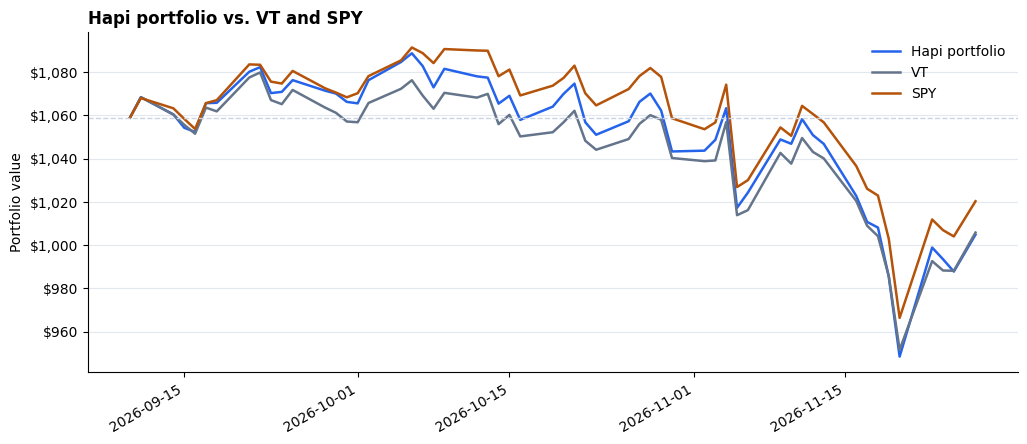

In [55]:
from matplotlib.ticker import StrMethodFormatter

benchmark_wealth = (
    benchmark_prices.div(benchmark_prices.iloc[0]) * portfolio_wealth.iloc[0]
)

wealth_comparison = pd.concat(
    [portfolio_wealth.rename("Hapi portfolio"), benchmark_wealth],
    axis=1,
)

ax = wealth_comparison.plot(
    figsize=(12, 5),
    color=["#2563EB", "#64748B", "#B45309"],
    linewidth=1.8,
)

ax.axhline(portfolio_wealth.iloc[0], color="#CBD5E1", ls="--", lw=1)
ax.set_title("Hapi portfolio vs. VT and SPY", loc="left", fontweight="bold")
ax.set(xlabel="", ylabel="Portfolio value")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.grid(axis="y", color="#E2E8F0")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.show()

In [56]:
positions = market_value.drop(columns="total")
start = positions.iloc[0]
end = positions.iloc[-1]
dates = positions.index.tz_localize(None).normalize()

cash_dividends = (
    transactions.loc[
        transactions["type"].eq("dividend")
        & transactions["date"].gt(dates[0])
        & transactions["date"].le(dates[-1])
    ]
    .groupby("ticker")["amount"]
    .sum()
    .reindex(start.index, fill_value=0)
)

vt = benchmark_prices["VT"].loc[[dates[0], dates[-1]]]
vt_return = vt.iloc[-1] / vt.iloc[0] - 1

pnl = end - start + cash_dividends

attribution = pd.DataFrame(
    {
        "Start weight (%)": 100 * start / start.sum(),
        "P&L ($)": pnl,
        "P&L vs VT ($)": pnl - start * vt_return,
    }
)

display(attribution.sort_values("P&L vs VT ($)").round(2))
print(f"Total gap vs VT: ${attribution['P&L vs VT ($)'].sum():+.2f}")

,Start weight (%),P&L ($),P&L vs VT ($)
NVDA,5.04,-16.59,-13.91
TSM,7.48,-13.67,-9.69
GOOGL,5.07,-9.30,-6.61
VT,49.73,-26.79,-0.33
FIDU,12.55,-3.80,2.88
AMZN,7.54,0.71,4.72
XLV,12.59,15.28,21.98


Total gap vs VT: $-0.95


## 3.3. What are the stat characteristicis of my approach at the time I constructed the portfolio?